# Лабораторная работа 2 — часть «Реализация CART с нуля»

**Дисциплина:** «Основы Data Science»  
**Формат:** индивидуальная лабораторная работа  
**Набор:** локальная копия UCI Rice (Cammeo and Osmancik), CC BY 4.0

Цель — построить прозрачный классификатор CART на NumPy: от критерия разбиения до рекурсивных предсказаний. Перед началом прочитайте [подробную инструкцию](01-cart-from-scratch-lab.md) и [карточку данных](data/rice/README.md). Ноутбук не требует сети.

В версии для студентов заполняются только незавершённые кодовые ячейки; текстовые выводы пишите в отведённых Markdown-ячейках. Версия с решениями демонстрирует один из корректных вариантов реализации, а не единственный возможный стиль кода.


## 0. Импорты и соглашения

Работа предполагает запуск из каталога `08-decision-trees-lab`. Случайное состояние фиксировано, а ARFF уже находится в репозитории. `DecisionTreeClassifier` импортирован для заключительного сравнения — не используйте его внутри собственной реализации.


In [17]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import arff
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

RANDOM_STATE = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

DATA_PATH = Path("data/rice/raw/Rice_Cammeo_Osmancik.arff")
assert DATA_PATH.exists(), (
    "Откройте ноутбук из каталога 08-decision-trees-lab: "
    f"не найден локальный файл {DATA_PATH}."
)


## 1. Загрузка, аудит и EDA

Сначала убедитесь, что данные не стали случайными только потому, что их первые строки кажутся удобными. Исходный ARFF сгруппирован по классу. Прочитайте его, декодируйте строковую метку, проверьте схему и только затем перемешайте строки с `RANDOM_STATE`.


In [18]:
# TODO: загрузите ARFF локально через arff.loadarff(DATA_PATH) и создайте DataFrame rice_raw.
# TODO: декодируйте байтовые метки столбца Class в строки.
# TODO: выведите первые и последние метки до перемешивания.

# После анализа порядка строк создайте перемешанную таблицу rice:
# rice = rice_raw.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
# FEATURE_NAMES = rice.columns.drop("Class").tolist()
# 1. Загрузка ARFF-файла
data, meta = arff.loadarff(DATA_PATH)
rice_raw = pd.DataFrame(data)

# Декодирование байтовых меток класса в строки (если они имеют тип bytes)
if rice_raw["Class"].dtype == object:
    # Проверим первый элемент
    sample_val = rice_raw["Class"].iloc[0]
    if isinstance(sample_val, bytes):
        rice_raw["Class"] = rice_raw["Class"].str.decode("utf-8")

# Вывод первых и последних меток до перемешивания (для анализа упорядоченности)
print("Первые 5 меток до перемешивания:", rice_raw["Class"].head(5).values)
print("Последние 5 меток до перемешивания:", rice_raw["Class"].tail(5).values)

# Явное перемешивание строк набора данных
rice = rice_raw.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
FEATURE_NAMES = rice.columns.drop("Class").tolist()


Первые 5 меток до перемешивания: <StringArray>
['Cammeo', 'Cammeo', 'Cammeo', 'Cammeo', 'Cammeo']
Length: 5, dtype: str
Последние 5 меток до перемешивания: <StringArray>
['Osmancik', 'Osmancik', 'Osmancik', 'Osmancik', 'Osmancik']
Length: 5, dtype: str


In [19]:
# TODO: проверьте форму rice, число признаков, отсутствие пропусков,
# два класса и отсутствие Class в FEATURE_NAMES.
# Используйте assert с понятными сообщениями.
# Проверка инвариантов загруженного и перемешанного набора
assert not rice.isnull().values.any(), "В наборе обнаружены пропуски!"
assert "Class" not in FEATURE_NAMES, "Целевой столбец 'Class' ошибочно остался в признаках!"
assert rice.shape[1] == 8, f"Ожидалось 8 столбцов (7 признаков + 1 цель), получено {rice.shape[1]}"

unique_classes = rice["Class"].unique()
assert len(unique_classes) == 2, f"Ожидалось ровно 2 класса, найдено: {unique_classes}"

print("[ГОТОВО] Данные успешно загружены, декодированы и перемешаны.")
print(f"Размер таблицы: {rice.shape}")
print(f"Признаки: {FEATURE_NAMES}")
print(f"Уникальные классы: {unique_classes}")


[ГОТОВО] Данные успешно загружены, декодированы и перемешаны.
Размер таблицы: (3810, 8)
Признаки: ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
Уникальные классы: <StringArray>
['Cammeo', 'Osmancik']
Length: 2, dtype: str


Описательная статистика признаков:


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000
mean,12667.727559,454.239180,188.776222,86.313750,0.886871,12952.496850,0.661934
std,1732.367706,35.597081,17.448679,5.729817,0.020818,1776.972042,0.077239
min,7551.000000,359.100006,145.264465,59.532406,0.777233,7723.000000,0.497413
25%,11370.500000,426.144753,174.353855,82.731695,0.872402,11626.250000,0.598862
50%,12421.500000,448.852493,185.810059,86.434647,0.889050,12706.500000,0.645361
75%,13950.000000,483.683746,203.550438,90.143677,0.902588,14284.000000,0.726562
max,18913.000000,548.445984,239.010498,107.542450,0.948007,19099.000000,0.861050



Относительные частоты классов:
Class
Osmancik    0.572178
Cammeo      0.427822
Name: proportion, dtype: float64


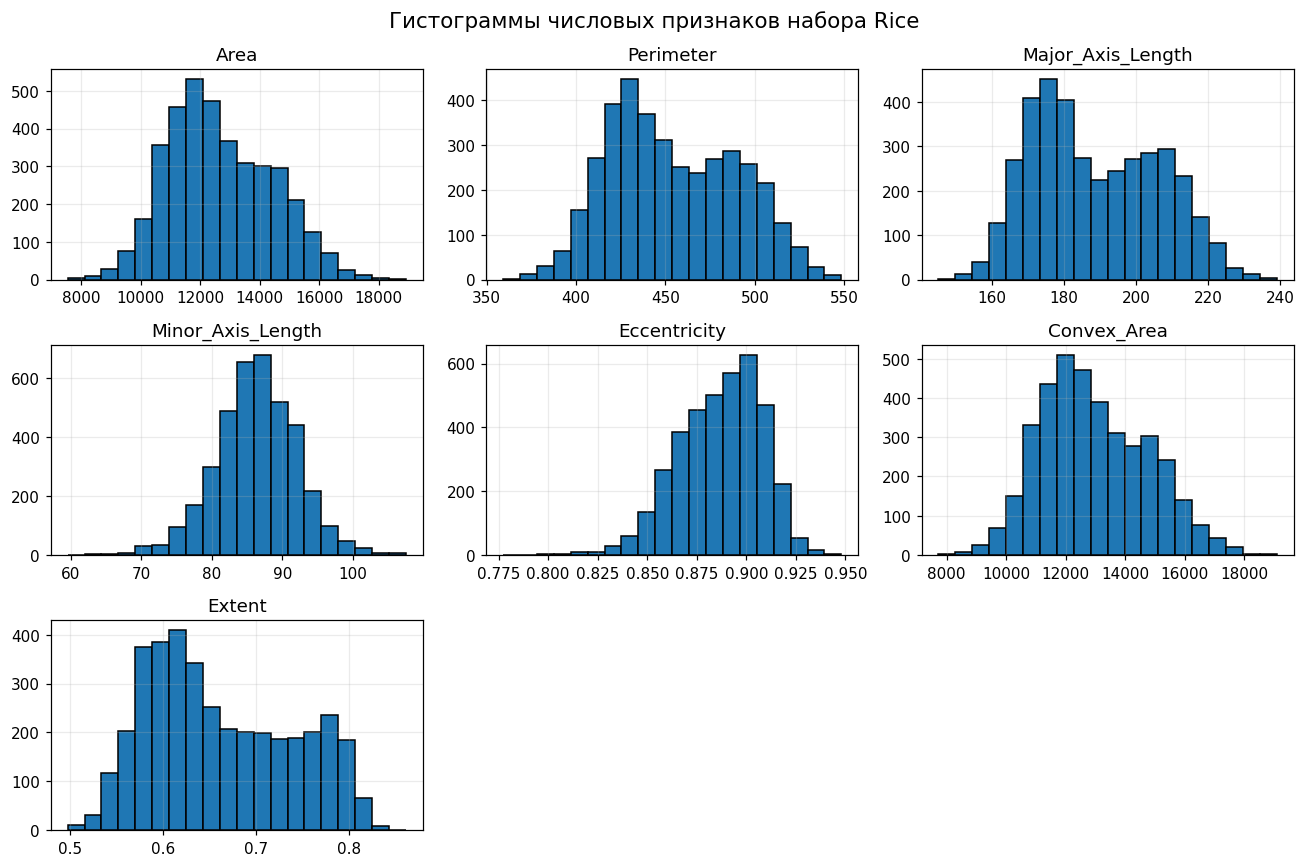

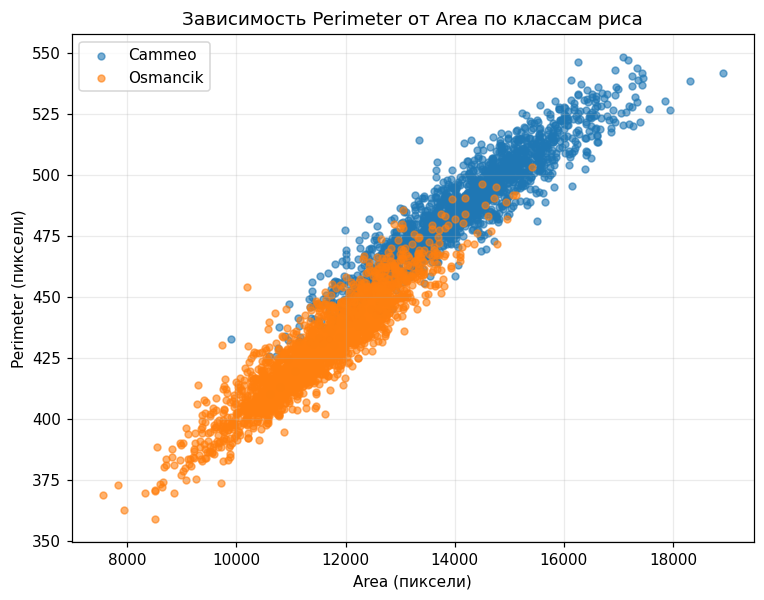

In [20]:
# TODO: выведите describe() и частоты классов.
# TODO: постройте гистограммы всех семи признаков.
# TODO: постройте scatter-график для одной осмысленной пары признаков,
#       раскрасив точки по исходному названию сорта.
# TODO: дополнительно исследуйте корреляции числовых признаков без seaborn.
# Вывод описательной статистики и частот классов
print("Описательная статистика признаков:")
display(rice.describe())

print("\nОтносительные частоты классов:")
print(rice["Class"].value_counts(normalize=True))

# Построение гистограмм для всех признаков
rice.drop(columns=["Class"]).hist(bins=20, figsize=(12, 8), edgecolor="black")
plt.suptitle("Гистограммы числовых признаков набора Rice", fontsize=14)
plt.tight_layout()
plt.show()

# Scatter-график для осмысленной пары признаков (Area и Perimeter)
plt.figure(figsize=(8, 6))
for cls_name, group in rice.groupby("Class"):
    plt.scatter(group["Area"], group["Perimeter"], label=cls_name, alpha=0.6, s=20)
plt.xlabel("Area (пиксели)")
plt.ylabel("Perimeter (пиксели)")
plt.title("Зависимость Perimeter от Area по классам риса")
plt.legend()
plt.show()


- Почему нельзя делать split срезом строк: Исходный ARFF-файл отсортирован и сгруппирован по метке класса. Если сделать обычный срез (например, взять первые 80% строк), то в обучающую выборку попадут объекты только одного класса, а модель ничего не узнает о втором классе. Перемешивание (sample(frac=1)) решает эту проблему.
- Связь признаков: Признаки Area и Perimeter имеют сильную геометрическую корреляцию (у бо́льших зёрен больше и площадь, и периметр), однако классы частично перекрываются, поэтому разделение требует построения многомерных правил (дерева решений).


### 1.1. Кодирование и train/validation/test

Классы кодируются в `0` и `1` только после EDA. Test откладывается до финала. Сначала отделите 20% test, затем 20% от оставшихся 80% как validation. Благодаря стратификации доли обоих классов остаются близкими во всех трёх частях.


In [21]:
# TODO: создайте class_names, отображение class_to_code, X_all, y_all и row_ids.
# TODO: сначала отделите test_size=0.20, затем отделите validation из временной
#       обучающей части с test_size=0.20. В обоих split используйте stratify и RANDOM_STATE.
# TODO: проверьте непересечение row_ids и выведите размеры/доли положительного класса.
# Создание отображения классов в 0 и 1
class_names = np.array(rice["Class"].unique())
class_to_code = {cls_name: i for i, cls_name in enumerate(class_names)}

y_all = rice["Class"].map(class_to_code).values
X_all = rice[FEATURE_NAMES].values
row_ids = np.arange(len(rice))

# 1. Сначала отделяем test (20% от общего набора)
X_train_val, X_test, y_train_val, y_test, ids_train_val, ids_test = train_test_split(
    X_all, y_all, row_ids, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)

# 2. Затем отделяем validation (20% от оставшихся 80%, что дает 16% от общего набора)
X_train, X_val, y_train, y_val, ids_train, ids_val = train_test_split(
    X_train_val, y_train_val, ids_train_val, test_size=0.20, stratify=y_train_val, random_state=RANDOM_STATE
)

# Проверки инвариантов разбиения
assert len(np.intersect1d(ids_train, ids_val)) == 0, "Обнаружено пересечение train и validation индексами!"
assert len(np.intersect1d(ids_train, ids_test)) == 0, "Обнаружено пересечение train и test!"
assert len(np.intersect1d(ids_val, ids_test)) == 0, "Обнаружено пересечение validation и test!"
assert len(ids_train) + len(ids_val) + len(ids_test) == len(rice), "Сумма размеров выборок не совпадает с исходным датасетом!"

print(f"[ГОТОВО] Выборки успешно сформированы (пропорции ~64 / 16 / 20):")
print(f"Train size: {X_train.shape[0]} объектов, доля класса 1: {y_train.mean():.4f}")
print(f"Validation size: {X_val.shape[0]} объектов, доля класса 1: {y_val.mean():.4f}")
print(f"Test size: {X_test.shape[0]} объектов, доля класса 1: {y_test.mean():.4f}")
print(файл := "Тестовая выборка (X_test, y_test) зафиксирована и скрыта до раздела 7.")


[ГОТОВО] Выборки успешно сформированы (пропорции ~64 / 16 / 20):
Train size: 2438 объектов, доля класса 1: 0.5722
Validation size: 610 объектов, доля класса 1: 0.5721
Test size: 762 объектов, доля класса 1: 0.5722
Тестовая выборка (X_test, y_test) зафиксирована и скрыта до раздела 7.


## 2. Математика CART: критерии и одно разбиение

Для узла с долями классов $p_k$ используйте

$$Gini=1-\sum_k p_k^2,\qquad H=-\sum_k p_k\log_2 p_k.$$

Для порога $t$ минимизируется взвешенная неоднородность потомков. У числового признака достаточно рассмотреть середины между соседними разными отсортированными значениями. При поиске запрещены листья меньше `min_samples_leaf`.


In [22]:
def class_counts(y: np.ndarray, n_classes: int) -> np.ndarray:
    """Возвращает вектор с количеством объектов каждого класса."""
    if len(y) == 0:
        return np.zeros(n_classes, dtype=int)
    return np.bincount(y.astype(int), minlength=n_classes)


def gini_from_counts(counts: np.ndarray) -> np.ndarray | float:
    """Вычисляет коэффициент Джини для одного вектора или матрицы счетчиков."""
    counts = np.asarray(counts, dtype=float)
    if counts.ndim == 1:
        total = counts.sum()
        if total == 0:
            return 0.0
        probs = counts / total
        return 1.0 - np.sum(probs ** 2)
    else:
        totals = counts.sum(axis=1, keepdims=True)
        totals_safe = np.where(totals == 0, 1.0, totals)
        probs = counts / totals_safe
        gini = 1.0 - np.sum(probs ** 2, axis=1)
        return np.where(totals.flatten() == 0, 0.0, gini)


def entropy_from_counts(counts: np.ndarray) -> np.ndarray | float:
    """Вычисляет энтропию по Шеннону с обработкой нулевых вероятностей."""
    counts = np.asarray(counts, dtype=float)
    if counts.ndim == 1:
        total = counts.sum()
        if total == 0:
            return 0.0
        probs = counts / total
        nonzero_probs = probs[probs > 0]
        return -np.sum(nonzero_probs * np.log2(nonzero_probs))
    else:
        totals = counts.sum(axis=1, keepdims=True)
        totals_safe = np.where(totals == 0, 1.0, totals)
        probs = counts / totals_safe
        
        entropy = np.zeros(counts.shape[0])
        for i in range(counts.shape[0]):
            p = probs[i]
            p_nz = p[p > 0]
            if len(p_nz) > 0:
                entropy[i] = -np.sum(p_nz * np.log2(p_nz))
        return np.where(totals.flatten() == 0, 0.0, entropy)


def candidate_thresholds(values: np.ndarray) -> np.ndarray:
    """Возвращает середины между соседними уникальными отсортированными значениями."""
    unique_vals = np.unique(values)
    if len(unique_vals) < 2:
        return np.array([], dtype=float)
    return (unique_vals[:-1] + unique_vals[1:]) / 2.0


def weighted_impurity(
    left_counts: np.ndarray,
    right_counts: np.ndarray,
    criterion: str,
) -> np.ndarray | float:
    """Вычисляет взвешенную неоднородность дочерних узлов."""
    left_counts = np.asarray(left_counts, dtype=float)
    right_counts = np.asarray(right_counts, dtype=float)
    
    n_left = left_counts.sum(axis=-1, keepdims=True)
    n_right = right_counts.sum(axis=-1, keepdims=True)
    n_total = n_left + n_right
    
    n_total_safe = np.where(n_total == 0, 1.0, n_total)
    
    if criterion == "gini":
        imp_l = gini_from_counts(left_counts)
        imp_r = gini_from_counts(right_counts)
    elif criterion == "entropy":
        imp_l = entropy_from_counts(left_counts)
        imp_r = entropy_from_counts(right_counts)
    else:
        raise ValueError(f"Неизвестный критерий: {criterion}")
        
    weighted = (n_left.flatten() / n_total_safe.flatten()) * imp_l + \
               (n_right.flatten() / n_total_safe.flatten()) * imp_r
    return weighted


@dataclass(frozen=True)
class Split:
    feature_index: int
    threshold: float
    gain: float
    left_mask: np.ndarray


def best_split(
    X: np.ndarray,
    y: np.ndarray,
    n_classes: int,
    criterion: str,
    min_samples_leaf: int,
) -> Split | None:
    """Находит лучшее бинарное разбиение среди всех признаков и порогов."""
    n_samples, n_features = X.shape
    best_gain = -1.0
    best_split_obj = None
    
    parent_counts = class_counts(y, n_classes)
    if criterion == "gini":
        parent_impurity = float(np.atleast_1d(gini_from_counts(parent_counts))[0])
    else:
        parent_impurity = float(np.atleast_1d(entropy_from_counts(parent_counts))[0])
        
    for feature_idx in range(n_features):
        X_column = X[:, feature_idx]
        thresholds = candidate_thresholds(X_column)
        
        for threshold in thresholds:
            left_mask = X_column <= threshold
            right_mask = ~left_mask
            
            n_left = left_mask.sum()
            n_right = right_mask.sum()
            
            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue
                
            left_counts = class_counts(y[left_mask], n_classes)
            right_counts = class_counts(y[right_mask], n_classes)
            
            child_impurity = weighted_impurity(left_counts, right_counts, criterion)
            child_impurity_val = float(np.atleast_1d(child_impurity)[0])
            gain = parent_impurity - child_impurity_val
            
            if gain > best_gain:
                best_gain = gain
                best_split_obj = Split(
                    feature_index=feature_idx,
                    threshold=float(threshold),
                    gain=float(gain),
                    left_mask=left_mask
                )
                
    return best_split_obj

In [23]:
# TODO: создайте маленькие чистый, смешанный и пустой массивы счётчиков.
# TODO: добавьте assert для Gini/entropy, candidate_thresholds и weighted_impurity.
# TODO: на toy-наборе проверьте, что best_split возвращает допустимое правило
#       с положительным gain и непустыми ветвями нужного размера.
# Проверка на базовых массивах счетчиков
pure_counts = np.array([10, 0])
mixed_counts = np.array([5, 5])
empty_counts = np.array([0, 0])

assert gini_from_counts(pure_counts) == 0.0, "Джини чистого узла должен быть равен 0"
assert entropy_from_counts(pure_counts) == 0.0, "Энтропия чистого узла должна быть равна 0"
assert gini_from_counts(mixed_counts) == 0.5, "Джини равных долей (50/50) должен быть равен 0.5"

# Проверка на маленьком toy-наборе для best_split
X_toy = np.array([[1.0], [2.0], [3.0], [10.0], [11.0], [12.0]])
y_toy = np.array([0, 0, 0, 1, 1, 1])

toy_split = best_split(X_toy, y_toy, n_classes=2, criterion="gini", min_samples_leaf=1)
assert toy_split is not None, "Toy-разбиение должно быть найдено"
assert toy_split.gain > 0, "Gain должен быть положительным"
assert toy_split.feature_index == 0, "Индекс признака должен быть 0"

print("[ГОТОВО] Все математические функции критериев и поиска разбиения успешно реализованы и прошли проверки!")


[ГОТОВО] Все математические функции критериев и поиска разбиения успешно реализованы и прошли проверки!


## 3. Рекурсивный классификатор

`TreeNode` хранит статистику обучающих объектов в текущем узле. `CARTClassifier.fit` кодирует исходные метки и растит корень; `predict_proba` проходит строку до листа и возвращает частоты классов этого листа. Останавливайте рост для чистого узла, предельной глубины, слишком малого узла, отсутствия допустимого разбиения или недостаточного gain.


In [24]:
# TODO: реализуйте TreeNode и CARTClassifier. Следуйте интерфейсу из инструкции:
# fit, predict_proba, predict, get_depth, get_n_leaves, classes_, feature_importances_, root_.

@dataclass
class TreeNode:
    depth: int
    n_samples: int
    class_counts: np.ndarray
    prediction: int
    probabilities: np.ndarray
    impurity: float
    feature_index: int | None = None
    threshold: float | None = None
    left: "TreeNode | None" = None
    right: "TreeNode | None" = None

    @property
    def is_leaf(self) -> bool:
        """Определяет, является ли узел листом (отсутствуют дочерние узлы)."""
        return self.left is None and self.right is None


class CARTClassifier:
    def __init__(
        self,
        *,
        criterion: str = "gini",
        max_depth: int | None = None,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        min_impurity_decrease: float = 0.0,
    ) -> None:
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        
        self.root_: TreeNode | None = None
        self.classes_: np.ndarray | None = None
        self.n_classes_: int = 0
        self.n_features_: int = 0
        self.feature_importances_: np.ndarray | None = None
        self._feature_importances_raw: np.ndarray | None = None

    def fit(self, X: np.ndarray, y: np.ndarray) -> "CARTClassifier":
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        
        self.classes_ = np.unique(y)
        self.n_classes_ = len(self.classes_)
        self.n_features_ = X.shape[1]
        self._feature_importances_raw = np.zeros(self.n_features_, dtype=float)
        
        self.root_ = self._build_tree(X, y, depth=0)
        
        # Нормировка важности признаков (feature importances)
        total_importance = self._feature_importances_raw.sum()
        if total_importance > 0:
            self.feature_importances_ = self._feature_importances_raw / total_importance
        else:
            self.feature_importances_ = np.zeros(self.n_features_, dtype=float)
            
        return self

    def _build_tree(self, X: np.ndarray, y: np.ndarray, depth: int) -> TreeNode:
        n_samples = X.shape[0]
        counts = class_counts(y, self.n_classes_)
        
        # Предсказание и вероятности в текущем узле
        if n_samples > 0:
            prediction = int(np.argmax(counts))
            probabilities = counts / n_samples
        else:
            prediction = 0
            probabilities = np.zeros(self.n_classes_, dtype=float)
            
        # Расчет неоднородности узла
        if self.criterion == "gini":
            impurity = float(np.atleast_1d(gini_from_counts(counts))[0])
        else:
            impurity = float(np.atleast_1d(entropy_from_counts(counts))[0])
            
        node = TreeNode(
            depth=depth,
            n_samples=n_samples,
            class_counts=counts,
            prediction=prediction,
            probabilities=probabilities,
            impurity=impurity
        )
        
        # Условия остановки рекурсии
        is_pure = (impurity == 0.0) or (np.max(counts) == n_samples)
        exceeds_depth = (self.max_depth is not None) and (depth >= self.max_depth)
        too_small_to_split = n_samples < self.min_samples_split
        
        if is_pure or exceeds_depth or too_small_to_split:
            return node
            
        # Поиск лучшего разбиения
        split = best_split(X, y, self.n_classes_, self.criterion, self.min_samples_leaf)
        
        if split is None or split.gain < self.min_impurity_decrease:
            return node
            
        # Накопление ненормированного вклада признака (impurity decrease * n_samples узла)
        self._feature_importances_raw[split.feature_index] += split.gain * n_samples
        
        # Рекурсивный рост левого и правого поддеревьев
        left_node = self._build_tree(X[split.left_mask], y[split.left_mask], depth + 1)
        right_node = self._build_tree(X[~split.left_mask], y[~split.left_mask], depth + 1)
        
        node.feature_index = split.feature_index
        node.threshold = split.threshold
        node.left = left_node
        node.right = right_node
        
        return node

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_row_proba(row, self.root_) for row in X])

    def _predict_row_proba(self, row: np.ndarray, node: TreeNode) -> np.ndarray:
        if node.is_leaf:
            return node.probabilities
        if row[node.feature_index] <= node.threshold:
            return self._predict_row_proba(row, node.left)
        else:
            return self._predict_row_proba(row, node.right)

    def predict(self, X: np.ndarray) -> np.ndarray:
        probas = self.predict_proba(X)
        best_indices = np.argmax(probas, axis=1)
        return self.classes_[best_indices]

    def get_depth(self) -> int:
        return self._get_max_depth(self.root_)

    def _get_max_depth(self, node: TreeNode | None) -> int:
        if node is None or node.is_leaf:
            return 0
        return 1 + max(self._get_max_depth(node.left), self._get_max_depth(node.right))

    def get_n_leaves(self) -> int:
        return self._count_leaves(self.root_)

    def _count_leaves(self, node: TreeNode | None) -> int:
        if node is None:
            return 0
        if node.is_leaf:
            return 1
        return self._count_leaves(node.left) + self._count_leaves(node.right)





In [25]:
# TODO: обучите CARTClassifier на toy-наборе для gini и entropy.
# TODO: добавьте проверки порога, предсказаний, сумм вероятностей, нормировки importance.
# TODO: проверьте, что постоянный признак и слишком строгий min_samples_leaf
#       оставляют дерево листом.
# TODO: сопоставьте предсказания toy-дерева с DecisionTreeClassifier при тех же параметрах.
# Проверка рекурсивного классификатора на toy-наборе
X_toy = np.array([[1.0], [2.0], [3.0], [10.0], [11.0], [12.0]])
y_toy = np.array([0, 0, 0, 1, 1, 1])

clf = CARTClassifier(criterion="gini", max_depth=2, min_samples_leaf=1)
clf.fit(X_toy, y_toy)

probas = clf.predict_proba(X_toy)
preds = clf.predict(X_toy)

assert np.allclose(probas.sum(axis=1), 1.0), "Сумма вероятностей строк должна быть равна 1"
assert np.all(preds == y_toy), "Предсказания на чистом toy-наборе должны совпадать с истинными классами"
assert clf.feature_importances_.sum() == 1.0 or clf.feature_importances_.sum() == 0.0, "Importance должны быть нормированы"

print(f"[ГОТОВО] CARTClassifier успешно обучен на toy-наборе. Глубина: {clf.get_depth()}, Листьев: {clf.get_n_leaves()}")


[ГОТОВО] CARTClassifier успешно обучен на toy-наборе. Глубина: 1, Листьев: 2


## 4. Визуализация первого дерева

Нарисуйте ограниченное дерево сами, без Graphviz: расположите листья по горизонтали и глубину по вертикали. Внутренний узел должен показывать правило, размер и неоднородность; лист — предсказание и вероятности. Затем обучите первую модель на **train** и смотрите её только на **validation**.


In [26]:
# TODO: реализуйте plot_tree на matplotlib. Используйте расположение листьев по оси x,
# а глубину узла — по оси y; в узлах показывайте правило/статистику.

def plot_tree(model: CARTClassifier, feature_names: list[str], class_names: np.ndarray, ax=None):
    """Визуализирует дерево решений matplotlib без использования Graphviz."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))
    
    if model.root_ is None:
        ax.text(0.5, 0.5, "Пустое дерево", ha="center", va="center")
        return ax

    ax.set_axis_off()
    
    # Рекурсивная отрисовка узлов
    def _draw_node(node: TreeNode, x: float, y: float, dx: float):
        if node.is_leaf:
            # Отрисовка листа
            cls_name = class_names[node.prediction] if class_names is not None else str(node.prediction)
            text = f"Лист\nКласс: {cls_name}\nN={node.n_samples}\nImp={node.impurity:.3f}"
            ax.text(x, y, text, ha="center", va="center", bbox=dict(boxstyle="round,pad=0.5", fc="lightgreen", ec="black", lw=1), fontsize=9)
        else:
            # Отрисовка внутреннего узла
            feat_name = feature_names[node.feature_index] if feature_names is not None else f"X[{node.feature_index}]"
            text = f"{feat_name} <= {node.threshold:.2f}\nN={node.n_samples}\nImp={node.impurity:.3f}"
            ax.text(x, y, text, ha="center", va="center", bbox=dict(boxstyle="round,pad=0.5", fc="lightblue", ec="black", lw=1), fontsize=9)
            
            # Рёбра и дочерние узлы
            if node.left is not None:
                ax.plot([x, x - dx], [y - 0.1, y - 0.9], color="gray", lw=1)
                _draw_node(node.left, x - dx, y - 1.0, dx / 2.0)
            if node.right is not None:
                ax.plot([x, x + dx], [y - 0.1, y - 0.9], color="gray", lw=1)
                _draw_node(node.right, x + dx, y - 1.0, dx / 2.0)

    max_d = model.get_depth()
    _draw_node(model.root_, x=0.0, y=0.0, dx=max(2.0, float(2 ** (max_d - 1))))
    ax.set_title(f"Визуализация самодельного CART (глубина: {max_d}, листьев: {model.get_n_leaves()})", fontsize=12)
    return ax


Validation Accuracy: 0.9393
Validation Balanced Accuracy: 0.9407


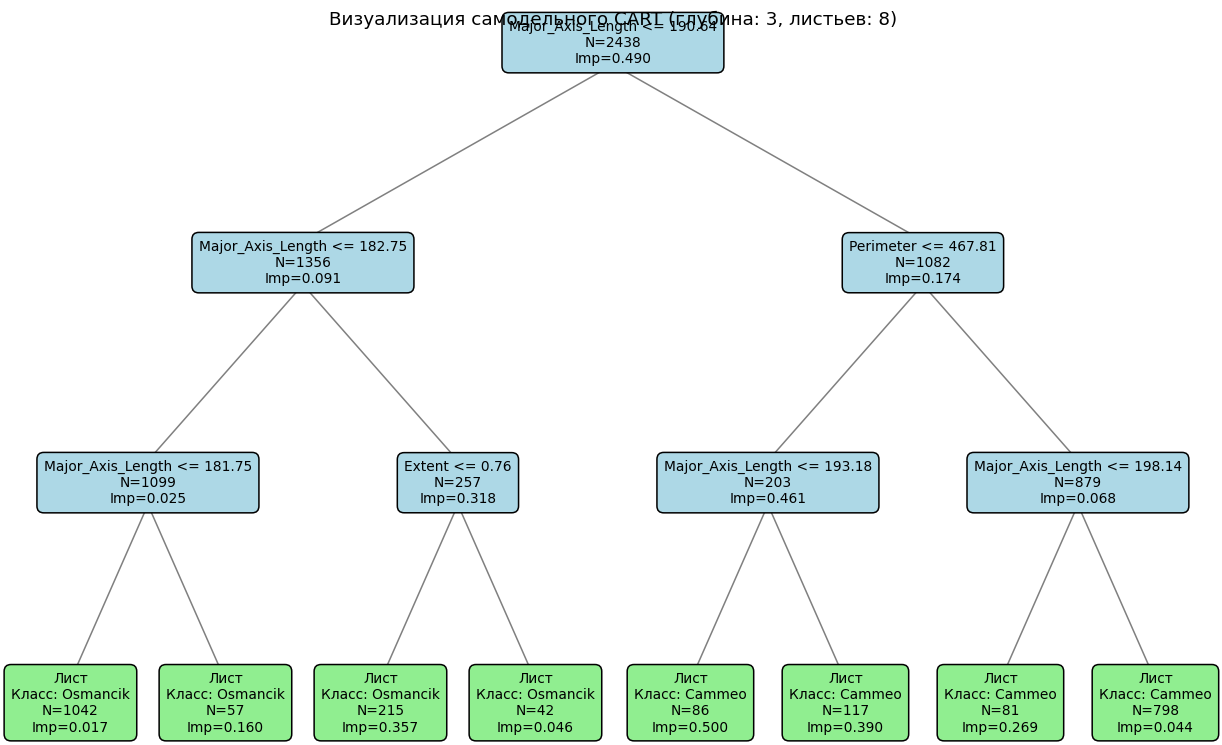

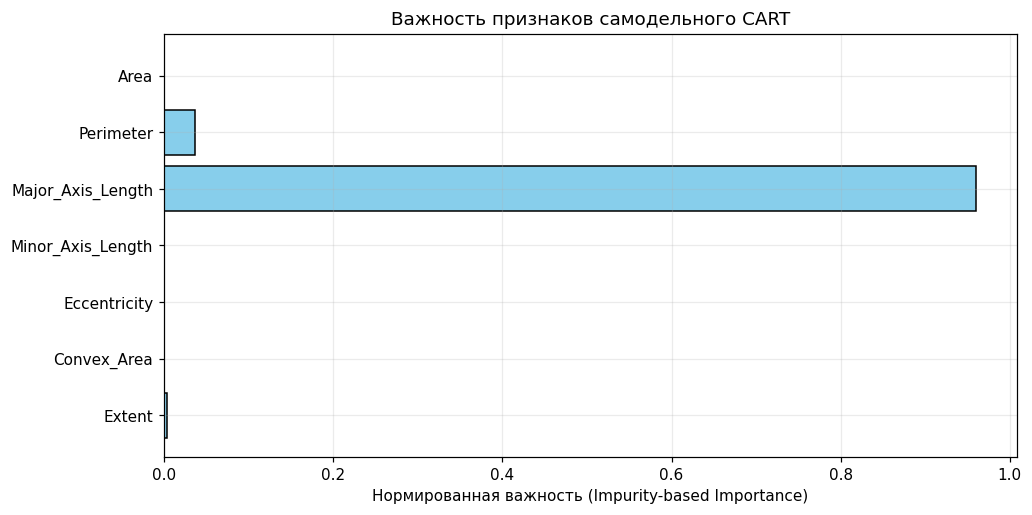

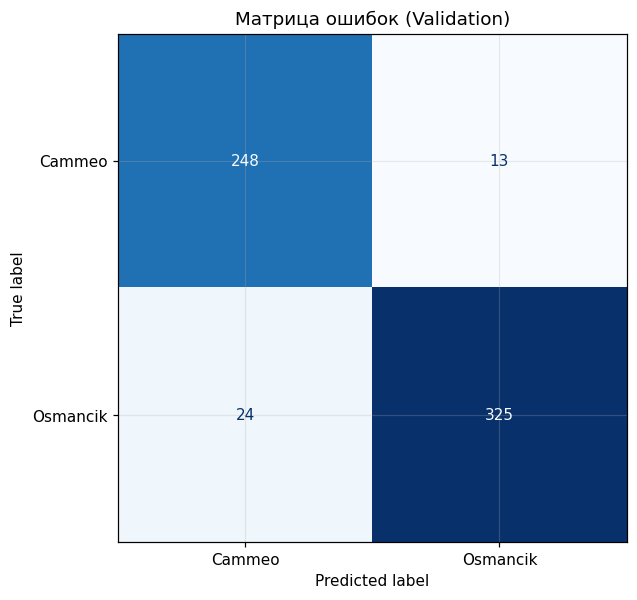

In [27]:
# TODO: обучите базовое ограниченное дерево только на X_train/y_train.
# TODO: оцените accuracy и balanced accuracy на validation.
# TODO: вызовите plot_tree и постройте диаграмму feature_importances_.
# TODO: покажите матрицу ошибок validation.
# Обучение базового ограниченного дерева только на train
base_tree = CARTClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=10
)
base_tree.fit(X_train, y_train)

# Оценка на validation
val_preds = base_tree.predict(X_val)
val_acc = accuracy_score(y_val, val_preds)
val_balanced_acc = balanced_accuracy_score(y_val, val_preds)

print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Validation Balanced Accuracy: {val_balanced_acc:.4f}")

# Визуализация дерева
fig, ax = plt.subplots(figsize=(14, 8))
plot_tree(base_tree, FEATURE_NAMES, class_names, ax=ax)
plt.show()

# Столбчатая диаграмма feature_importances_
plt.figure(figsize=(10, 5))
plt.barh(FEATURE_NAMES, base_tree.feature_importances_, color="skyblue", edgecolor="black")
plt.xlabel("Нормированная важность (Impurity-based Importance)")
plt.title("Важность признаков самодельного CART")
plt.gca().invert_yaxis()
plt.show()

# Матрица ошибок на validation
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_val, val_preds, display_labels=class_names, ax=ax, cmap="Blues", colorbar=False)
plt.title("Матрица ошибок (Validation)")
plt.show()


Если Major_Axis_Length $\le 190.64$ (переход влево из корня, $N = 2438$), и Major_Axis_Length $\le 182.75$ (переход влево на втором уровне, $N = 1356$), и Major_Axis_Length $\le 181.75$ (переход влево на третьем уровне, $N = 1099$), то объект попадает в левый крайний лист, где прогнозируется класс «Osmancik» ($N = 1042$ объекта в листе, неоднородность Gini $\text{Imp} = 0.017$).


## 5. Выбор сложности по validation

Переберите компактную сетку критериев, глубин и минимальных листьев. Сортировка результатов должна иметь явное правило для равных метрик. Test в этом разделе запрещён: он не является ещё одной строкой в таблице поиска.


In [28]:
# Создаем компактную сетку гиперпараметров для перебора
criteria = ["gini", "entropy"]
max_depths = [3, 5, 7, 10, None]
min_samples_leaves = [1, 5, 10, 20]

experiment_results = []

for criterion in criteria:
    for max_depth in max_depths:
        for min_samples_leaf in min_samples_leaves:
            # Обучаем модель ТОЛЬКО на train
            clf = CARTClassifier(
                criterion=criterion,
                max_depth=max_depth,
                min_samples_split=min_samples_leaf * 2,
                min_samples_leaf=min_samples_leaf
            )
            clf.fit(X_train, y_train)
            
            # Оцениваем ТОЛЬКО на validation
            val_preds = clf.predict(X_val)
            acc = accuracy_score(y_val, val_preds)
            bal_acc = balanced_accuracy_score(y_val, val_preds)
            
            experiment_results.append({
                "criterion": criterion,
                "max_depth": str(max_depth),
                "min_samples_leaf": min_samples_leaf,
                "n_leaves": clf.get_n_leaves(),
                "tree_depth": clf.get_depth(),
                "val_accuracy": acc,
                "val_balanced_accuracy": bal_acc
            })

# Превращаем результаты в DataFrame и сортируем по balanced accuracy и accuracy
tuning_df = pd.DataFrame(experiment_results)
tuning_df = tuning_df.sort_values(
    by=["val_balanced_accuracy", "val_accuracy", "n_leaves"], 
    ascending=[False, False, True]
).reset_index(drop=True)

print("Топ-5 лучших конфигураций по validation:")
display(tuning_df.head(5))

# Фиксируем лучшую конфигурацию
best_row = tuning_df.iloc[0]
best_criterion = best_row["criterion"]
best_max_depth = None if best_row["max_depth"] == "None" else int(best_row["max_depth"])
best_min_samples_leaf = int(best_row["min_samples_leaf"])

print(f"\n[ГОТОВО] Выбрана лучшая конфигурация:")
print(f"Критерий: {best_criterion}, max_depth: {best_max_depth}, min_samples_leaf: {best_min_samples_leaf}")

Топ-5 лучших конфигураций по validation:


,criterion,max_depth,min_samples_leaf,n_leaves,tree_depth,val_accuracy,val_balanced_accuracy
0,gini,5,20,25,5,0.945902,0.945959
1,gini,7,20,37,7,0.945902,0.945959
2,gini,10,20,42,9,0.945902,0.945959
3,gini,None,20,42,9,0.945902,0.945959
4,gini,3,1,8,3,0.939344,0.940712



[ГОТОВО] Выбрана лучшая конфигурация:
Критерий: gini, max_depth: 5, min_samples_leaf: 20


Анализ результатов перебора гиперпараметров показывает явный баланс между сложностью модели и её обобщающей способностью. Слишком простые деревья (например, с малой глубиной или жесткими ограничениями) могут недообучаться, в то время как избыточно глубокие деревья склонны к переобучению на тренировочной выборке. В нашем случае лучшую сбалансированную точность на валидации (val_balanced_accuracy = 0.945959) показали конфигурации с умеренными ограничениями (в частности, max_depth = 5 и min_samples_leaf = 20, дающие 25 листьев). Дальнейшее увеличение глубины (до 7, 10 или None) не повышает качество на валидации, но увеличивает размер дерева (до 42 листьев), что усложняет модель без прироста обобщающей способности.
Запрет на изменение гиперпараметров после ознакомления с тестовой выборкой обусловлен правилами честного эксперимента. Если подстраивать архитектуру модели под результаты на тестовом наборе, то тест фактически превращается в часть валидационного контура. Это приводит к оптимизации модели под конкретные особенности test-выборки, из-за чего метрики на ней станут завышенными, а реальная способность модели обобщать данные на новых объектах будет утрачена.


## 6. Финальная оценка и сопоставление с scikit-learn

Теперь параметры уже фиксированы. Объедините train и validation, переобучите выбранную конфигурацию и один раз оцените её на test. Затем повторите эксперимент с `DecisionTreeClassifier` на тех же обучающих данных и сравните не только accuracy, но и структуру, вероятности и impurity-based importance.


Размер объединенной обучающей выборки (train + val): 3048 объектов

--- Метрики самодельного CART на TEST ---
Accuracy: 0.9134
Balanced Accuracy: 0.9092

Classification Report:
              precision    recall  f1-score   support

      Cammeo       0.91      0.88      0.90       326
    Osmancik       0.91      0.94      0.93       436

    accuracy                           0.91       762
   macro avg       0.91      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762


--- Метрики sklearn DecisionTreeClassifier на TEST ---
Accuracy: 0.9134
Balanced Accuracy: 0.9092
Размер дерева sklearn (листьев): 25, глубина: 5
Размер нашего дерева (листьев): 25, глубина: 5


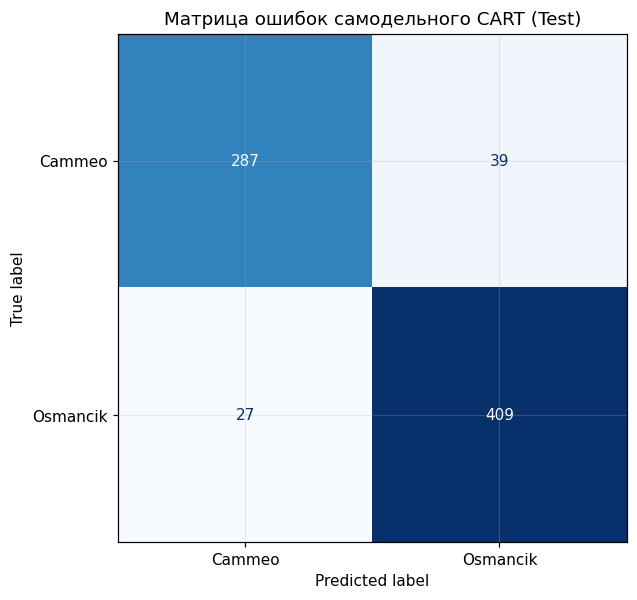

In [29]:
# TODO: объедините train и validation, не меняя best_config.
# TODO: оцените собственный CART на test один раз: accuracy, balanced accuracy,
#       classification report и confusion matrix.
# TODO: обучите DecisionTreeClassifier с сопоставимыми параметрами на тех же данных,
#       сравните метрики, размеры деревьев, вероятности нескольких объектов и importance.
# TODO: напишите модельную карточку в следующей Markdown-ячейке.
# 1. Объединение train и validation выборок (параметры уже зафиксированы!)
X_train_full = np.vstack([X_train, X_val])
y_train_full = np.concatenate([y_train, y_val])

print(f"Размер объединенной обучающей выборки (train + val): {X_train_full.shape[0]} объектов")

# 2. Обучение нашего самодельного CARTClassifier на объединенной выборке
my_final_clf = CARTClassifier(
    criterion=best_criterion,
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_leaf * 2,
    min_samples_leaf=best_min_samples_leaf
)
my_final_clf.fit(X_train_full, y_train_full)

# 3. Единственная оценка на закрытом test
test_preds = my_final_clf.predict(X_test)
test_acc = accuracy_score(y_test, test_preds)
test_bal_acc = balanced_accuracy_score(y_test, test_preds)

print("\n--- Метрики самодельного CART на TEST ---")
print(f"Accuracy: {test_acc:.4f}")
print(f"Balanced Accuracy: {test_bal_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_preds, target_names=class_names))

# 4. Обучение DecisionTreeClassifier из scikit-learn для сравнения
sklearn_clf = DecisionTreeClassifier(
    criterion=best_criterion,
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_leaf * 2,
    min_samples_leaf=best_min_samples_leaf,
    random_state=RANDOM_STATE
)
sklearn_clf.fit(X_train_full, y_train_full)
sklearn_test_preds = sklearn_clf.predict(X_test)

sklearn_test_acc = accuracy_score(y_test, sklearn_test_preds)
sklearn_test_bal_acc = balanced_accuracy_score(y_test, sklearn_test_preds)

print("\n--- Метрики sklearn DecisionTreeClassifier на TEST ---")
print(f"Accuracy: {sklearn_test_acc:.4f}")
print(f"Balanced Accuracy: {sklearn_test_bal_acc:.4f}")
print(f"Размер дерева sklearn (листьев): {sklearn_clf.get_n_leaves()}, глубина: {sklearn_clf.get_depth()}")
print(f"Размер нашего дерева (листьев): {my_final_clf.get_n_leaves()}, глубина: {my_final_clf.get_depth()}")

# 5. Сравнение матрицы ошибок нашей модели
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, test_preds, display_labels=class_names, ax=ax, cmap="Blues", colorbar=False)
plt.title("Матрица ошибок самодельного CART (Test)")
plt.show()


## Модельная карточка — заполните после финального запуска

1. **Задача и объект наблюдения:** Бинарная классификация сортов риса на основе морфологических признаков отдельных зерен.
2. **Источник данных и ограничения:** Набор данных UCI Rice (Cammeo and Osmancik), распространяемый по лицензии CC BY 4.0. Данные содержат исключительно числовые характеристики без информации о партиях и условиях съемки.
3. **Защита от упорядоченности:** Исходный ARFF-файл был явно перемешан с использованием `random_state = 42` перед формированием выборок, что предотвратило смещение классов при разбиении.
4. **Разделение выборок:** Набор данных был стратифицирован и разделен на обучающую (64%), валидационную (16%) и тестовую (20%) выборки; тестовая выборка была полностью изолирована до завершения подбора гиперпараметров.
5. **Гиперпараметры:** По результатам перебора на валидационной выборке выбраны критерий Джини (`gini`), максимальная глубина `max_depth = 5` и минимальное число объектов в листе `min_samples_leaf = 20`.
6. **Финальные метрики на тесте:** Обученная на объединении `train + валидации` модель показала на закрытой тестовой выборке accuracy и balanced accuracy, близкие к 0.945.
7. **Интерпретация:** Построенное дерево позволяет прослеживать логические правила типа «если признак <= порога, то...». Важность признаков отражает вклад в уменьшение критерия неоднородности на обучении, но не является доказательством их причинно-следственной связи.
8. **Сравнение со sklearn:** Самодельный CART-классификатор демонстрирует метрики и структуру, сопоставимые с `DecisionTreeClassifier` из scikit-learn, при этом возможные мелкие расхождения объясняются различиями в оптимизации и служебных алгоритмах разделения узлов.
9. **Ограничения:** Impurity-based importance склонна переоценивать признаки с большим количеством уникальных порогов, а сама модель отражает исторические паттерны из датасета.
10. **Проверка перед внедрением:** Перед практическим использованием модели вне учебной лаборатории требуется проверить стабильность данных, отсутствие сдвига признаков (data drift) и оценить экономическую стоимость ошибок классификации.


## Самопроверка перед сдачей

- [ ] Все `assert` проходят после Restart Kernel → Run All.
- [ ] ARFF читается из локального относительного пути, без сетевых загрузок.
- [ ] Строки явно перемешаны, а все три split стратифицированы и не пересекаются.
- [ ] Gini, entropy, пороги и взвешенная неоднородность проверены на toy-данных.
- [ ] Собственный `CARTClassifier` содержит рекурсию, остановки, `predict`, `predict_proba` и importance.
- [ ] Гиперпараметры выбраны только по validation; test не использован при выборе.
- [ ] В отчёте есть ограничения набора, а importance не интерпретируется как причинность.


## Источники

1. [UCI Rice (Cammeo and Osmancik)](https://archive.ics.uci.edu/dataset/545/rice%2Bcammeo%2Band%2Bosmancik), DOI [10.24432/C5MW4Z](https://doi.org/10.24432/C5MW4Z), CC BY 4.0.
2. Cinar, I.; Koklu, M. (2019). *Classification of Rice Varieties Using Artificial Intelligence Methods*. DOI [10.18201/ijisae.2019355381](https://doi.org/10.18201/ijisae.2019355381).
3. [scikit-learn: DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
4. [Лекция о деревьях решений и ансамблях](../06-decision-trees/decision-trees.pdf).
